# Day 15 – Agent Harness: the runtime around the model

**Simple idea:** the LLM is only the "brain". A real agent also needs a **body and rules** around it: which tools it may use,
how long it may run, what to do when something breaks, what to remember, what needs a human's permission, and a record of
everything it did. That runtime is called the **agent harness** (Claude Code is a big example of one).

In this notebook the Day 14 agent becomes a **reusable harness**:

| Part | What it means (simple) |
|---|---|
| 1. Harness core | Tools plug in with one line; settings for system prompt, step / token budgets, timeouts; errors go back to the model instead of crashing |
| 2. Context & memory | When the conversation gets too long, old parts are **summarised**; a small **long-term memory** file keeps facts between sessions |
| 3. Guardrails | Tools are **safe** or **sensitive**; sensitive ones (write a file, send an email) need **your approval**; Python code runs in a **sandbox** |
| 4. Tracing & comparison | Every run is logged (steps, tokens, time, cost); the same agent is rebuilt with **LangGraph** and compared |

**Runtime:** CPU is enough (no GPU). **Model:** Gemini. If `GEMINI_API_KEY` is in Colab Secrets the Gemini API is used;
otherwise Colab's built-in Gemini is used (no key needed).

## 0. Setup

In [1]:
!pip install -q -U google-genai ddgs langgraph

import os, re, json, time, math, ast, uuid, datetime, subprocess, tempfile, textwrap, inspect
import concurrent.futures as cf
from dataclasses import dataclass, field
import pandas as pd
import matplotlib.pyplot as plt
import requests

RPM = 10                       # max LLM calls per minute (free tier)
PRICE_PER_M = {"in": 0.0, "out": 0.0}   # US$ per 1M tokens; fill in from the pricing page to see real cost

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.1 which is incompatible.


## 1. The model backend
The harness talks to the model through **one small function**: `llm(prompt) -> (text, tokens_in, tokens_out)`.
Because of this, the model can be swapped (Gemini API, Colab built-in, a local model) without touching the harness.
The model answers in a simple **JSON action format**: either "use this tool" or "here is the final answer".

In [2]:
client, MODEL, colab_ai = None, None, None
try:
    from google.colab import userdata
    key = userdata.get("GEMINI_API_KEY")
except Exception:
    key = os.environ.get("GEMINI_API_KEY")

if key:
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=key)
    names = [m.name.split("/")[-1] for m in client.models.list()]
    MODEL = next((m for m in ["gemini-2.5-flash", "gemini-2.0-flash", "gemini-flash-latest"] if m in names), "gemini-2.5-flash")
    print("Backend: Gemini API,", MODEL)
else:
    from google.colab import ai as colab_ai
    MODEL = "Gemini (Colab built-in)"
    print("Backend: Colab built-in Gemini (token counts are estimated as characters / 4)")

_last = [0.0]
def llm(prompt):
    """Call the model once. Returns (text, tokens_in, tokens_out). Retries on rate limits."""
    for attempt in range(5):
        wait = 60 / RPM - (time.time() - _last[0])
        if wait > 0: time.sleep(wait)
        _last[0] = time.time()
        try:
            if client:
                cfg = types.GenerateContentConfig(temperature=0, response_mime_type="application/json")
                r = client.models.generate_content(model=MODEL, contents=prompt, config=cfg)
                u = r.usage_metadata
                return (r.text or ""), (u.prompt_token_count or 0), (u.candidates_token_count or 0) + (getattr(u, "thoughts_token_count", 0) or 0)
            text = colab_ai.generate_text(prompt)
            return text, len(prompt) // 4, len(text) // 4
        except Exception as e:
            if any(k in str(e) for k in ["429", "RESOURCE_EXHAUSTED", "503", "UNAVAILABLE", "500"]):
                print("   rate limit / busy, waiting 30s"); time.sleep(30)
            else:
                raise
    raise RuntimeError("Model kept failing")

print(llm('Reply with JSON only: {"ok": true}')[0])

Backend: Colab built-in Gemini (token counts are estimated as characters / 4)
{"ok": true}


## 2. Harness core: tool registry
A **tool registry** is like a phone book of tools. Adding a tool = one decorator line.
Each tool says: its name, what it does, its inputs (JSON schema), whether it is **sensitive**, and its **timeout**.

In [3]:
@dataclass
class Tool:
    name: str
    fn: callable
    description: str
    parameters: dict
    sensitive: bool = False      # needs human approval before running
    timeout: float = 15.0        # seconds

class ToolRegistry:
    def __init__(self):
        self.tools = {}

    def tool(self, description, parameters=None, sensitive=False, timeout=15.0):
        """Decorator: @registry.tool("what it does", {...schema...})"""
        def wrap(fn):
            self.tools[fn.__name__] = Tool(fn.__name__, fn, description,
                                           parameters or {"type": "object", "properties": {}}, sensitive, timeout)
            return fn
        return wrap

    def schemas(self):
        return {t.name: {"description": t.description, "parameters": t.parameters,
                         "needs_approval": t.sensitive} for t in self.tools.values()}

registry = ToolRegistry()
print("Registry ready")

Registry ready


### The tools
- **Safe:** `calculator`, `web_search`, `get_today`, `save_memory`, `recall_memory`, `run_python` (runs in a sandbox)
- **Sensitive (need approval):** `write_file`, `send_email` (**simulated**: it only writes to `outbox.txt`, nothing is really sent)
- `slow_tool`: takes 10 seconds on purpose, to test the **timeout**

In [4]:
# ---------- safe maths ----------
SAFE_FUNCS = {"sqrt": math.sqrt, "round": round, "abs": abs, "log": math.log, "pow": pow, "min": min, "max": max}
def _ev(n):
    if isinstance(n, ast.Constant) and isinstance(n.value, (int, float)): return n.value
    if isinstance(n, ast.BinOp):
        ops = {ast.Add: lambda a, b: a + b, ast.Sub: lambda a, b: a - b, ast.Mult: lambda a, b: a * b,
               ast.Div: lambda a, b: a / b, ast.Pow: lambda a, b: a ** b, ast.Mod: lambda a, b: a % b, ast.FloorDiv: lambda a, b: a // b}
        return ops[type(n.op)](_ev(n.left), _ev(n.right))
    if isinstance(n, ast.UnaryOp) and isinstance(n.op, ast.USub): return -_ev(n.operand)
    if isinstance(n, ast.Call) and getattr(n.func, "id", None) in SAFE_FUNCS: return SAFE_FUNCS[n.func.id](*[_ev(a) for a in n.args])
    raise ValueError("only maths is allowed")

@registry.tool("Calculate a maths expression exactly. Use it for ALL arithmetic.",
               {"type": "object", "properties": {"expression": {"type": "string"}}, "required": ["expression"]})
def calculator(expression):
    v = _ev(ast.parse(re.sub(r"(?<=\d),(?=\d{3})", "", expression).replace("^", "**"), mode="eval").body)
    return str(round(v, 6) if isinstance(v, float) else v)

@registry.tool("Search the web for facts about the world. Returns short snippets.",
               {"type": "object", "properties": {"query": {"type": "string"}}, "required": ["query"]}, timeout=25)
def web_search(query):
    try:
        from ddgs import DDGS
        hits = DDGS().text(query, max_results=3)
        if hits:
            return "\n".join(f"- {h['title']}: {h['body']}" for h in hits)
    except Exception:
        pass
    api, H = "https://en.wikipedia.org/w/api.php", {"User-Agent": "day15-harness-intern-project/1.0"}
    s = requests.get(api, headers=H, timeout=15, params={"action": "query", "list": "search", "srsearch": query, "format": "json", "srlimit": 2}).json()
    titles = [r["title"] for r in s["query"]["search"]]
    if not titles: return "No results."
    x = requests.get(api, headers=H, timeout=15, params={"action": "query", "prop": "extracts", "exintro": 1, "explaintext": 1,
                     "titles": "|".join(titles), "format": "json"}).json()
    return "\n".join(f"- {p['title']}: {p.get('extract', '')[:600]}" for p in x["query"]["pages"].values())

@registry.tool("Return today's date.")
def get_today():
    return datetime.date.today().strftime("%A, %d %B %Y")

@registry.tool("Waits 10 seconds (used only to test timeouts).", timeout=3)
def slow_tool():
    time.sleep(10); return "finished"

### Long-term memory (survives between sessions)
A simple **JSON file** of facts. The agent can **save** a fact and **recall** facts later, even in a brand-new session.
Recall uses simple word overlap (a vector store, like Day 13, would be the bigger version).

In [5]:
MEMORY_FILE = "agent_memory.json"

def _load_mem():
    try:
        return json.load(open(MEMORY_FILE))
    except Exception:
        return []

@registry.tool("Save an important fact to long-term memory so it can be recalled in future sessions.",
               {"type": "object", "properties": {"fact": {"type": "string"}}, "required": ["fact"]})
def save_memory(fact):
    mem = _load_mem()
    mem.append({"fact": fact, "saved": datetime.datetime.now().isoformat(timespec="seconds")})
    json.dump(mem, open(MEMORY_FILE, "w"), indent=1)
    return f"Saved. Memory now has {len(mem)} facts."

@registry.tool("Search long-term memory for facts saved in earlier sessions.",
               {"type": "object", "properties": {"query": {"type": "string"}}, "required": ["query"]})
def recall_memory(query):
    words = set(re.findall(r"\w+", query.lower())) - {"the", "a", "is", "my", "what", "of", "to"}
    scored = sorted(((len(words & set(re.findall(r"\w+", m["fact"].lower()))), m["fact"]) for m in _load_mem()), reverse=True)
    hits = [f for s, f in scored if s > 0][:3]
    return "\n".join(f"- {h}" for h in hits) if hits else "No matching memories."

### Sandbox for code
`run_python` runs code in a **separate, isolated Python process**: its own empty temp folder, a **5-second time limit**,
a **256 MB memory limit**, no access to this notebook's variables, and it cannot see your Colab secrets.
(A production sandbox would also block the network, e.g. with Docker or a VM.)

In [6]:
import resource

def _limits():
    resource.setrlimit(resource.RLIMIT_AS, (256 * 1024 ** 2, 256 * 1024 ** 2))   # 256 MB memory
    resource.setrlimit(resource.RLIMIT_CPU, (5, 5))                               # 5 s CPU time

@registry.tool("Run a short Python program in a sandbox and return what it prints. Use print() to show results.",
               {"type": "object", "properties": {"code": {"type": "string"}}, "required": ["code"]}, timeout=10)
def run_python(code):
    with tempfile.TemporaryDirectory() as box:
        path = os.path.join(box, "main.py")
        open(path, "w").write(code)
        env = {"PATH": "/usr/bin:/bin", "HOME": box}            # no secrets, no notebook variables
        p = subprocess.run(["python3", "-I", path], cwd=box, env=env, capture_output=True, text=True,
                           timeout=8, preexec_fn=_limits)
        out = (p.stdout + p.stderr).strip()
        return out[-1500:] if out else "(no output)"

print(run_python("print(sum(range(10)))"))
print(run_python("import os; print(os.environ.get('GEMINI_API_KEY', 'secret not visible'))"))

45
secret not visible


### Sensitive tools (need approval)
These would change things in the real world, so the harness asks a human first.
`send_email` is **simulated**: it only appends to `outbox.txt`.

In [7]:
@registry.tool("Write text to a file in the 'agent_files' folder.",
               {"type": "object", "properties": {"filename": {"type": "string"}, "content": {"type": "string"}},
                "required": ["filename", "content"]}, sensitive=True)
def write_file(filename, content):
    os.makedirs("agent_files", exist_ok=True)
    safe = os.path.basename(filename)                       # no "../" tricks: stays inside agent_files/
    open(os.path.join("agent_files", safe), "w").write(content)
    return f"Wrote {len(content)} characters to agent_files/{safe}"

@registry.tool("Send an email (SIMULATED: saved to outbox.txt, nothing is really sent).",
               {"type": "object", "properties": {"to": {"type": "string"}, "subject": {"type": "string"}, "body": {"type": "string"}},
                "required": ["to", "subject", "body"]}, sensitive=True)
def send_email(to, subject, body):
    with open("outbox.txt", "a") as f:
        f.write(f"TO: {to}\nSUBJECT: {subject}\n{body}\n---\n")
    return f"Email to {to} saved to outbox.txt (simulated)."

pd.DataFrame([{"tool": t.name, "sensitive": t.sensitive, "timeout_s": t.timeout, "description": t.description[:70]}
              for t in registry.tools.values()])

,tool,sensitive,timeout_s,description
0,calculator,False,15.0,Calculate a maths expression exactly. Use it f...
1,web_search,False,25.0,Search the web for facts about the world. Retu...
2,get_today,False,15.0,Return today's date.
3,slow_tool,False,3.0,Waits 10 seconds (used only to test timeouts).
4,save_memory,False,15.0,Save an important fact to long-term memory so ...
5,recall_memory,False,15.0,Search long-term memory for facts saved in ear...
6,run_python,False,10.0,Run a short Python program in a sandbox and re...
7,write_file,True,15.0,Write text to a file in the 'agent_files' folder.
8,send_email,True,15.0,"Send an email (SIMULATED: saved to outbox.txt,..."


## 3. The harness
One class that runs the loop and enforces all the rules:
- **Budgets:** stop after `max_steps` model calls or `token_budget` tokens
- **Timeouts:** every tool runs with its own time limit
- **Error recovery:** bad JSON from the model, unknown tools, tool crashes and timeouts all go **back to the model as text**
- **Approval:** sensitive tools call `approve(...)` first
- **Context management:** when the history is longer than `max_context_tokens`, older steps are **summarised** (or cut if that fails)
- **Tracing:** every step is recorded and the whole run is saved to `traces.jsonl`

In [8]:
DEFAULT_SYSTEM = """You are a helpful assistant agent. Solve the task step by step using tools.
- Use calculator for ALL arithmetic. Use run_python for anything that needs a program.
- When the user asks you to remember something, call save_memory. When a question might be about earlier sessions, call recall_memory.
- If a tool returns an error, read it and try a different approach.
- If an action is denied by the user, do not try it again; explain what you could not do.
Reply with ONE JSON object only, either:
{"thought": "<one short sentence>", "tool": "<tool name>", "args": {...}}
or
{"thought": "<one short sentence>", "final_answer": "<answer for the user>"}"""

def ask_human(tool_name, args):
    print(f"\n  ⚠️  The agent wants to run a SENSITIVE tool: {tool_name}({json.dumps(args)[:300]})")
    return input("  Approve? (y/n): ").strip().lower().startswith("y")

APPROVAL = {"ask": ask_human, "deny": lambda t, a: False, "approve": lambda t, a: True}

class Harness:
    def __init__(self, registry, llm, system_prompt=DEFAULT_SYSTEM, max_steps=8, token_budget=40_000,
                 max_context_tokens=2_500, approval="ask", trace_file="traces.jsonl", verbose=True):
        self.registry, self.llm, self.system_prompt = registry, llm, system_prompt
        self.max_steps, self.token_budget, self.max_context_tokens = max_steps, token_budget, max_context_tokens
        self.approve = APPROVAL[approval] if isinstance(approval, str) else approval
        self.trace_file, self.verbose = trace_file, verbose

    # ----- helpers -----
    def _say(self, *a):
        if self.verbose: print(*a)

    @staticmethod
    def _est(text):
        return len(text) // 4

    def _prompt(self, task, history):
        tools = json.dumps(self.registry.schemas(), indent=1)
        hist = "\n".join(history) if history else "(nothing yet)"
        return f"{self.system_prompt}\n\nTOOLS:\n{tools}\n\nTASK: {task}\n\nHISTORY:\n{hist}\n\nYour next JSON:"

    def _parse(self, text):
        t = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.M).strip()
        m = re.search(r"\{.*\}", t, flags=re.S)
        d = json.loads(m.group(0) if m else t)
        if not isinstance(d, dict) or not ({"tool", "final_answer"} & d.keys()):
            raise ValueError("JSON must contain 'tool' or 'final_answer'")
        return d

    def _run_tool(self, name, args):
        tool = self.registry.tools.get(name)
        if tool is None:
            return f"ERROR: unknown tool '{name}'. Available: {list(self.registry.tools)}", "error"
        if tool.sensitive and not self.approve(name, args):
            return f"DENIED: the user did not approve '{name}'. Do not try it again.", "denied"
        ex = cf.ThreadPoolExecutor(max_workers=1)
        fut = ex.submit(tool.fn, **(args or {}))
        try:
            return str(fut.result(timeout=tool.timeout))[:2000], "ok"
        except cf.TimeoutError:
            return f"ERROR: '{name}' timed out after {tool.timeout}s. Try something else.", "timeout"
        except Exception as e:
            return f"ERROR in {name}: {type(e).__name__}: {e}", "error"
        finally:
            ex.shutdown(wait=False, cancel_futures=True)     # don't wait for a stuck tool

    def _manage_context(self, history, trace):
        """Keep the prompt small: summarise old history when it gets too long."""
        if self._est("\n".join(history)) <= self.max_context_tokens or len(history) <= 3:
            return history
        old, recent = history[:-2], history[-2:]
        try:
            text, tin, tout = self.llm("Summarise these agent steps in 3-5 short bullet points. Keep every number, "
                                       "fact and tool result that may still be needed. Reply as plain text.\n\n" + "\n".join(old))
            trace["tokens_in"] += tin; trace["tokens_out"] += tout
            summary = "SUMMARY OF EARLIER STEPS:\n" + text.strip()[:1500]
            kind = "summarised"
        except Exception:
            summary, kind = "(earlier steps were cut to save space)", "truncated"
        trace["context_events"].append({"type": kind, "messages_replaced": len(old)})
        self._say(f"  📦 context {kind}: {len(old)} old messages -> 1 summary")
        return [summary] + recent

    # ----- main loop -----
    def run(self, task):
        trace = {"run_id": uuid.uuid4().hex[:8], "task": task, "model": MODEL, "started": datetime.datetime.now().isoformat(timespec="seconds"),
                 "steps": [], "tokens_in": 0, "tokens_out": 0, "context_events": [], "stop_reason": None, "answer": None}
        history, t_run = [], time.time()
        self._say(f"\n▶ TASK: {task}")
        for step in range(1, self.max_steps + 1):
            if trace["tokens_in"] + trace["tokens_out"] > self.token_budget:
                trace["stop_reason"] = "token_budget"; break
            history = self._manage_context(history, trace)
            t0 = time.time()
            try:
                text, tin, tout = self.llm(self._prompt(task, history))
            except Exception as e:
                trace["stop_reason"] = f"model_error: {e}"; break
            trace["tokens_in"] += tin; trace["tokens_out"] += tout
            rec = {"step": step, "llm_seconds": round(time.time() - t0, 2), "tokens_in": tin, "tokens_out": tout}
            try:
                d = self._parse(text)
            except Exception as e:
                rec.update(type="bad_output", detail=str(e)[:150]); trace["steps"].append(rec)
                history.append(f"Assistant (invalid): {text[:200]}\nSYSTEM: invalid reply ({e}). Reply with ONE valid JSON object.")
                self._say(f"  [{step}] ⚠️ invalid JSON, asking again"); continue
            thought = d.get("thought", "")
            if "final_answer" in d:
                rec.update(type="final", thought=thought); trace["steps"].append(rec)
                trace["answer"], trace["stop_reason"] = str(d["final_answer"]), "final_answer"
                self._say(f"  [{step}] ✅ FINAL: {trace['answer']}")
                break
            name, args = d.get("tool"), d.get("args") or {}
            t1 = time.time()
            result, status = self._run_tool(name, args)
            rec.update(type="tool", thought=thought, tool=name, args=args, status=status,
                       tool_seconds=round(time.time() - t1, 2), result=result[:300])
            trace["steps"].append(rec)
            self._say(f"  [{step}] 🧠 {thought}\n       🔧 {name}({json.dumps(args)[:120]}) -> [{status}] {result[:110].replace(chr(10), ' ')}")
            history.append(f"Assistant: {json.dumps(d)}\nTool result ({name}, {status}): {result[:1200]}")
        else:
            trace["stop_reason"] = "max_steps"
        if trace["stop_reason"] != "final_answer":
            self._say(f"  ⛔ stopped: {trace['stop_reason']}")
        trace["seconds"] = round(time.time() - t_run, 1)
        trace["cost_usd"] = (trace["tokens_in"] * PRICE_PER_M["in"] + trace["tokens_out"] * PRICE_PER_M["out"]) / 1e6
        with open(self.trace_file, "a") as f:
            f.write(json.dumps(trace, default=str) + "\n")
        return trace

print("Harness ready")

Harness ready


## 4. Test the harness, one feature at a time
Each test checks one part of the task. (Delete `traces.jsonl` and `agent_memory.json` to start fresh.)

### 4a. Normal multi-step task + error recovery + timeout

In [9]:
h = Harness(registry, llm, approval="deny")
runs = []
runs.append(h.run("What is the square root of the year the Eiffel Tower was completed, rounded to 2 decimals?"))
runs.append(h.run("First call slow_tool. If it fails, just tell me what 2 to the power of 20 is."))
runs.append(h.run("Use run_python to print the 20th Fibonacci number (fib(1)=1, fib(2)=1)."))


▶ TASK: What is the square root of the year the Eiffel Tower was completed, rounded to 2 decimals?
  [1] 🧠 I need to find the year the Eiffel Tower was completed, then calculate its square root.
       🔧 web_search({"query": "When was the Eiffel Tower completed?"}) -> [ok] - Eiffel Tower - Wikipedia: The Eiffel Tower (/ ˈaɪfəl / ⓘ EYE-fəl; French: Tour Eiffel [tuʁ ɛfɛl] ⓘ) is a lat
  [2] 🧠 The Eiffel Tower was completed in 1889; now I will calculate the square root of 1889.
       🔧 calculator({"expression": "sqrt(1889)"}) -> [ok] 43.462628
  [3] ✅ FINAL: The Eiffel Tower was completed in 1889, and its square root, rounded to two decimal places, is 43.46.

▶ TASK: First call slow_tool. If it fails, just tell me what 2 to the power of 20 is.
  [1] 🧠 I will execute the slow_tool as requested.
       🔧 slow_tool({}) -> [timeout] ERROR: 'slow_tool' timed out after 3s. Try something else.
  [2] 🧠 The slow_tool timed out, so I will calculate 2 to the power of 20 using the calculator.
      

### 4b. Long-term memory across two **separate** sessions
Session 1 saves facts. Session 2 is a **new harness object** with an empty conversation, so it can only know the answer from the memory file.

In [10]:
session1 = Harness(registry, llm, approval="deny")
runs.append(session1.run("Please remember these two facts: my project deadline is Friday 14 November, "
                         "and my favourite programming language is Python."))

session2 = Harness(registry, llm, approval="deny")      # brand new session
runs.append(session2.run("What is my project deadline? Check what you remember from before."))
print("\nMemory file now contains:", json.dumps(_load_mem(), indent=1)[:500])


▶ TASK: Please remember these two facts: my project deadline is Friday 14 November, and my favourite programming language is Python.
  [1] 🧠 I will save the provided facts into long-term memory.
       🔧 save_memory({"fact": "The user's project deadline is Friday 14 November and their favourite programming language is Python."}) -> [ok] Saved. Memory now has 1 facts.
  [2] ✅ FINAL: I have remembered that your project deadline is Friday 14 November and your favourite programming language is Python.

▶ TASK: What is my project deadline? Check what you remember from before.
  [1] 🧠 I will search my memory for information regarding a project deadline.
       🔧 recall_memory({"query": "project deadline"}) -> [ok] - The user's project deadline is Friday 14 November and their favourite programming language is Python.
  [2] ✅ FINAL: Your project deadline is Friday, 14 November.

Memory file now contains: [
 {
  "fact": "The user's project deadline is Friday 14 November and their favourite pro

### 4c. Guardrails: human-in-the-loop
First with an **automatic deny** policy, then with **you** deciding: type `y` or `n` in the box that appears.

In [11]:
runs.append(Harness(registry, llm, approval="deny").run(
    "Send an email to team@example.com with subject 'Daily update' saying the harness is working."))

print("\n----- Now YOU decide (type y or n when asked) -----")
runs.append(Harness(registry, llm, approval="ask").run(
    "Write a file called notes.txt that contains three bullet points about what an agent harness is."))
print("\nFiles written by the agent:", os.listdir("agent_files") if os.path.exists("agent_files") else "none")


▶ TASK: Send an email to team@example.com with subject 'Daily update' saying the harness is working.
  [1] 🧠 I will send an email to the specified address with the requested subject and body.
       🔧 send_email({"to": "team@example.com", "subject": "Daily update", "body": "The harness is working."}) -> [denied] DENIED: the user did not approve 'send_email'. Do not try it again.
  [2] ✅ FINAL: I am sorry, but I cannot send the email because the action was denied by you.

----- Now YOU decide (type y or n when asked) -----

▶ TASK: Write a file called notes.txt that contains three bullet points about what an agent harness is.
  [1] 🧠 I need to search for information about an agent harness to provide accurate points for the file.
       🔧 web_search({"query": "what is an agent harness"}) -> [ok] - Agent harness - Wikipedia: An agent harness, also known as agent scaffolding, is the software infrastructure

  ⚠️  The agent wants to run a SENSITIVE tool: write_file({"filename": "notes.txt"

### 4d. Context management
A long task with a **very small context limit** (150 tokens) so the harness is forced to summarise old steps.

In [12]:
small = Harness(registry, llm, approval="deny", max_context_tokens=150, max_steps=10)
runs.append(small.run("Using calculator for each step: compute 17*23, then add 345, then multiply by 3, "
                      "then subtract 1000, then divide by 7. Give every intermediate result in the final answer."))
print("Context events:", runs[-1]["context_events"])


▶ TASK: Using calculator for each step: compute 17*23, then add 345, then multiply by 3, then subtract 1000, then divide by 7. Give every intermediate result in the final answer.
  [1] 🧠 I will calculate the first step, 17 * 23.
       🔧 calculator({"expression": "17 * 23"}) -> [ok] 391
  [2] 🧠 I will calculate the next step by adding 345 to 391.
       🔧 calculator({"expression": "391 + 345"}) -> [ok] 736
  [3] 🧠 I will calculate the next step by multiplying 736 by 3.
       🔧 calculator({"expression": "736 * 3"}) -> [ok] 2208
  [4] 🧠 I will calculate the next step by subtracting 1000 from 2208.
       🔧 calculator({"expression": "2208 - 1000"}) -> [ok] 1208
  📦 context summarised: 2 old messages -> 1 summary
  [5] 🧠 I will calculate the final step by dividing 1208 by 7.
       🔧 calculator({"expression": "1208 / 7"}) -> [ok] 172.571429
  📦 context summarised: 2 old messages -> 1 summary
  [6] ✅ FINAL: The calculations were as follows: 17 * 23 = 391; 391 + 345 = 736; 736 * 3 = 2208; 

## 5. Tracing: what happened in every run
Each run is saved in `traces.jsonl` (one JSON line per run): steps, tool status, tokens, time, cost.

,run,task,stop,steps,tool_calls,errors/timeouts,denied,context_events,tokens,seconds,cost_usd
0,575bae5c,What is the square root of the year the Eiffel...,final_answer,3,2,0,0,0,3369,14.9,0.0
1,860b79f0,"First call slow_tool. If it fails, just tell m...",final_answer,3,2,1,0,0,2709,20.2,0.0
2,fedde1cc,Use run_python to print the 20th Fibonacci num...,final_answer,2,1,0,0,0,1813,10.0,0.0
3,c50c90d0,Please remember these two facts: my project de...,final_answer,2,1,0,0,0,1837,13.1,0.0
4,b4dd4a39,What is my project deadline? Check what you re...,final_answer,2,1,0,0,0,1779,11.0,0.0
5,233b6e5b,Send an email to team@example.com with subject...,final_answer,2,1,0,1,0,1829,13.0,0.0
6,4992fd0c,Write a file called notes.txt that contains th...,final_answer,3,2,0,0,0,3530,183.0,0.0
7,f4414bc4,"Using calculator for each step: compute 17*23,...",final_answer,6,5,0,0,2,6163,67.0,0.0


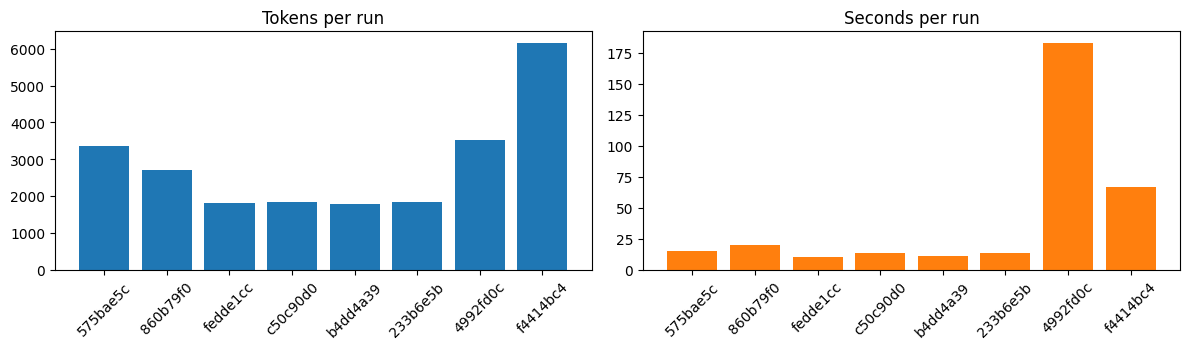


One full trace (first run):
{
 "run_id": "575bae5c",
 "task": "What is the square root of the year the Eiffel Tower was completed, rounded to 2 decimals?",
 "model": "Gemini (Colab built-in)",
 "started": "2026-11-03T05:32:39",
 "steps": [
  {
   "step": 1,
   "llm_seconds": 2.9,
   "tokens_in": 824,
   "tokens_out": 45,
   "type": "tool",
   "thought": "I need to find the year the Eiffel Tower was completed, then calculate its square root.",
   "tool": "web_search",
   "args": {
    "query": "When was the Eiffel Tower completed?"
   },
   "status": "ok",
   "tool_seconds": 2.1,
   "result": "- Eiffel Tower - Wikipedia: The Eiffel Tower (/ \u02c8a\u026af\u0259l / \u24d8 EYE-f\u0259l; French: Tour Eiffel [tu\u0281 \u025bf\u025bl] \u24d8) is a lattice tower on the Champ de Mars in Paris, France. It is named after the engineer Gustave Eiffel, whose company designed and built the tower from 1887 to 1889.\n- Eiffel Tower | History, Heigh"
  },
  {
   "step": 2,
   "llm_seconds": 3.04,
   "

In [13]:
summary = pd.DataFrame([{
    "run": t["run_id"], "task": t["task"][:55] + "...", "stop": t["stop_reason"], "steps": len(t["steps"]),
    "tool_calls": sum(s["type"] == "tool" for s in t["steps"]),
    "errors/timeouts": sum(s.get("status") in ("error", "timeout") for s in t["steps"]),
    "denied": sum(s.get("status") == "denied" for s in t["steps"]),
    "context_events": len(t["context_events"]),
    "tokens": t["tokens_in"] + t["tokens_out"], "seconds": t["seconds"], "cost_usd": round(t["cost_usd"], 5)}
    for t in runs])
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(summary.run, summary.tokens, color="tab:blue"); ax[0].set_title("Tokens per run"); ax[0].tick_params(axis="x", rotation=45)
ax[1].bar(summary.run, summary.seconds, color="tab:orange"); ax[1].set_title("Seconds per run"); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

print("\nOne full trace (first run):")
print(json.dumps(runs[0], indent=1, default=str)[:1800])

## 6. The same agent rebuilt with a framework: LangGraph
LangGraph describes an agent as a **graph**: a `model` node decides, a `tools` node acts, and an arrow goes back until the answer is ready.
To compare fairly it uses the **same model, prompt and tools**, but only the framework's own features (no approval, timeouts or memory management added).

In [14]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END

class AgentState(TypedDict):
    task: str
    history: List[str]
    decision: dict
    answer: str

def model_node(state):
    text, _, _ = llm(h._prompt(state["task"], state["history"]))
    try:
        d = h._parse(text)
    except Exception:
        d = {"tool": "none", "args": {}}
    return {"decision": d, "answer": str(d.get("final_answer", ""))}

def tools_node(state):
    d = state["decision"]
    tool = registry.tools.get(d.get("tool"))
    try:
        result = str(tool.fn(**(d.get("args") or {}))) if tool else "unknown tool"
    except Exception as e:
        result = f"ERROR: {e}"
    return {"history": state["history"] + [f"Assistant: {json.dumps(d)}\nTool result: {result[:1200]}"]}

def route(state):
    return END if "final_answer" in state["decision"] else "tools"

graph = StateGraph(AgentState)
graph.add_node("model", model_node)
graph.add_node("tools", tools_node)
graph.add_edge(START, "model")
graph.add_conditional_edges("model", route)
graph.add_edge("tools", "model")
lg_agent = graph.compile()

lg_results = []
for task in ["What is the square root of the year the Eiffel Tower was completed, rounded to 2 decimals?",
             "Use run_python to print the 20th Fibonacci number (fib(1)=1, fib(2)=1)."]:
    t0 = time.time()
    try:
        out = lg_agent.invoke({"task": task, "history": [], "decision": {}, "answer": ""}, {"recursion_limit": 17})
        ans = out["answer"]
    except Exception as e:
        ans = f"STOPPED: {type(e).__name__}"
    lg_results.append({"task": task[:60] + "...", "answer": ans[:120], "seconds": round(time.time() - t0, 1)})
    print("LangGraph:", lg_results[-1])

LangGraph: {'task': 'What is the square root of the year the Eiffel Tower was com...', 'answer': 'The square root of the year the Eiffel Tower was completed (1889) is approximately 43.46.', 'seconds': 21.1}
LangGraph: {'task': 'Use run_python to print the 20th Fibonacci number (fib(1)=1,...', 'answer': 'The 20th Fibonacci number is 6765.', 'seconds': 13.6}


### Comparison: my harness vs LangGraph

In [15]:
def loc(fns):
    try:
        return sum(len(inspect.getsource(f).splitlines()) for f in fns)
    except Exception:
        return "n/a"
my_loc = loc([f for f in vars(Harness).values() if inspect.isfunction(f)])
lg_loc = loc([model_node, tools_node, route])
lg_loc = lg_loc + 9 if isinstance(lg_loc, int) else lg_loc       # + 9 lines of graph wiring

comparison = pd.DataFrame([
    ["Lines of code (agent loop)", my_loc, lg_loc],
    ["Step limit", "max_steps (graceful stop + reason)", "recursion_limit (raises an error)"],
    ["Token budget", "built in", "not built in (write it yourself)"],
    ["Tool timeouts", "per tool", "not built in"],
    ["Errors go back to the model", "yes, with a status", "only what I code in the node"],
    ["Human approval", "per tool (sensitive flag)", "possible with interrupts, more setup"],
    ["Context summarising", "built in", "not built in"],
    ["Trace file", "every run, every step", "needs LangSmith or custom code"],
    ["Visual structure", "plain Python loop", "clear graph (nodes + edges), easy to extend with branches"],
], columns=["", "My harness", "LangGraph"])
display(comparison)

,,My harness,LangGraph
0,Lines of code (agent loop),96,26
1,Step limit,max_steps (graceful stop + reason),recursion_limit (raises an error)
2,Token budget,built in,not built in (write it yourself)
3,Tool timeouts,per tool,not built in
4,Errors go back to the model,"yes, with a status",only what I code in the node
5,Human approval,per tool (sensitive flag),"possible with interrupts, more setup"
6,Context summarising,built in,not built in
7,Trace file,"every run, every step",needs LangSmith or custom code
8,Visual structure,plain Python loop,"clear graph (nodes + edges), easy to extend wi..."


## My notes (write in your own words)

**What is an agent harness, and why does an agent need one?**

-It is the runtime around the LLM. It controls the tools, budgets, timeouts, errors, memory, permissions and logs. Without it, an agent could loop forever, crash on errors, or do dangerous things without asking

**Which harness feature was the most useful in my tests? (look at section 4 and 5)**

-Error recovery with timeouts. When slow_tool timed out, the agent read the error and switched to the calculator instead of crashing.

**What happened when I denied a sensitive action?**

-The email was not sent. The agent did not try again and explained to me that it could not send it because I did not approve.

**My harness vs LangGraph: which would I use, and why?**

-LangGraph needs much less code (26 vs 96 lines) and is easy to read. But my harness already has budgets, timeouts, approvals, summaries and traces built in. For learning and full control I’d use my harness; for a bigger project I’d use LangGraph and add these features.